# 01. Dataset del router de solicitudes

Este notebook describe el dataset usado para ajustar Granite 4.2 3B como router de un agente orquestador de una agencia peruana de viajes y eventos. Cada ejemplo contiene el mensaje de un cliente y el JSON que el router debe producir con la intención, el agente destino, la prioridad, la necesidad de aprobación humana y cuatro slots.

El proceso de construcción tuvo cuatro etapas.

1. Se redactó una guía de etiquetado (`docs/guia_etiquetado.md`) con ocho intenciones, ocho atributos factuales y cuatro slots.
2. Se construyeron 1000 mensajes en diez lotes independientes de 100 mensajes. Ocho lotes cubren subdominios distintos (viajes nacionales en familia, internacionales, escolares, corporativos, celebraciones, aventura, adultos mayores y jóvenes). Dos lotes, denominados gold, se concentran en mensajes con varias intenciones, urgencia implícita, montos en jerga y fronteras entre clases.
3. En cada mensaje se anotaron solo la intención, los atributos factuales y los slots. Las etiquetas `agente`, `prioridad` y `requiere_aprobacion_humana` se derivan con reglas deterministas de `src/router/esquema.py`, lo que garantiza consistencia total en esos campos.
4. Un segundo etiquetado independiente, sin acceso a las etiquetas originales, cubrió 150 mensajes elegidos al azar para medir el acuerdo entre etiquetadores.

In [1]:
import sys, json, collections
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score
from router import esquema, graficos

graficos.aplicar_estilo()
pd.set_option("display.max_colwidth", 120)

def leer_jsonl(ruta):
    with open(ruta, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

splits = {s: leer_jsonl(f"../data/processed/{s}.jsonl") for s in ("train", "val", "test")}
filas = []
for s, datos in splits.items():
    for f in datos:
        filas.append({"split": s, "id": f["id"], "texto": f["texto"], "origen": f["origen"], "dificultad": f["dificultad"],
                      **{k: f["salida"][k] for k in ("intencion", "agente", "prioridad", "requiere_aprobacion_humana")},
                      **{f"slot_{k}": f["salida"]["slots"][k] for k in esquema.SLOTS}})
df = pd.DataFrame(filas)
df["palabras"] = df["texto"].str.split().str.len()
print(f"{len(df)} ejemplos")
df.groupby(["split", "origen"]).size().unstack(fill_value=0)

999 ejemplos


origen,gold,lote
split,,
test,96,100
train,88,619
val,16,80


## Partición

Los splits se construyeron con `scripts/construir_splits.py`. Primero se eliminaron casi duplicados con similitud de Jaccard mayor o igual a 0.7 sobre 5-gramas de caracteres, lo que descartó un mensaje. Luego se estratificó por intención dentro de cada origen. El split de test concentra la mitad de los ejemplos gold porque contiene los casos más difíciles y representa mejor el uso real. El split de validación se usa para elegir learning rates y capacidad, y el de test se reserva para el reporte final.

## Ejemplos

In [2]:
df[df.split == "test"].sample(6, random_state=3)[["texto", "intencion", "agente", "prioridad", "requiere_aprobacion_humana"]]

,texto,intencion,agente,prioridad,requiere_aprobacion_humana
837,"Tuvimos un accidente con el buggy en Huacachina, mi esposa se golpeó la cabeza y está sangrando, necesitamos una amb...",emergencia_en_viaje,seguridad,P1,True
828,"Resérvame vuelo + hotel a Bariloche para julio, somos 2. Te paso mi pasaporte: Jorge Salas Ríos, 119876543. ¿Necesit...",reservar,logistica,P3,True
817,"Ya estamos en Arequipa con el paquete de ustedes. Sepárennos también el tour al Colca para 2, a nombre de Miguel y A...",reservar,logistica,P2,True
981,"Estamos en Máncora y hay alerta de tsunami, la gente está evacuando a la parte alta. Mi esposa, mis 2 hijos y yo ya ...",emergencia_en_viaje,seguridad,P1,True
924,El tour a las Islas Ballestas que ustedes mismos suspendieron por oleaje ya lo pagué y nadie me dice nada de mi plat...,pago_reembolso,finanzas,P2,True
890,"quiero pagar el saldo del quinceañero, son 3,500 soles, a qué número yapeo?",pago_reembolso,finanzas,P4,True


## Distribución de etiquetas

In [3]:
campos = ["intencion", "agente", "prioridad", "requiere_aprobacion_humana"]
tablas = {c: df.groupby([c, "split"]).size().unstack(fill_value=0)[["train", "val", "test"]] for c in campos}
for c, t in tablas.items():
    display(t.assign(total=t.sum(axis=1)))

split,train,val,test,total
intencion,,,,
cancelar,85,12,24,121
consulta_info,84,12,24,120
cotizar,92,12,25,129
emergencia_en_viaje,85,12,24,121
modificar,92,12,25,129
pago_reembolso,92,12,25,129
reclamo,85,12,24,121
reservar,92,12,25,129


split,train,val,test,total
agente,,,,
clima_info,49,9,19,77
finanzas,110,13,25,148
humano,145,18,39,202
logistica,364,49,98,511
seguridad,39,7,15,61


split,train,val,test,total
prioridad,,,,
P1,85,12,24,121
P2,307,37,93,437
P3,154,30,41,225
P4,161,17,38,216


split,train,val,test,total
requiere_aprobacion_humana,,,,
False,377,54,99,530
True,330,42,97,469


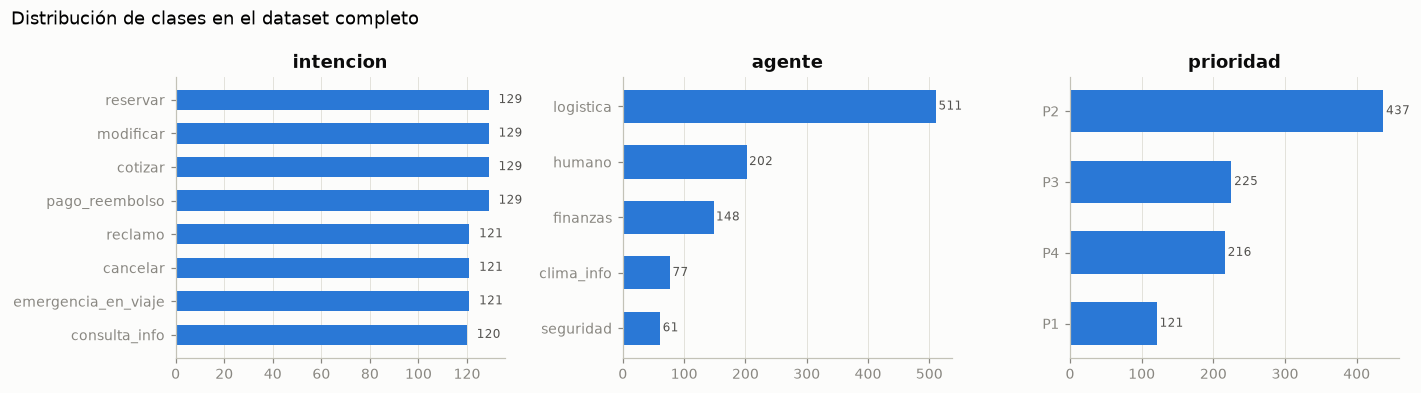

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(ejes, ["intencion", "agente", "prioridad"]):
    conteo = df[c].value_counts().sort_values()
    ax.barh(conteo.index, conteo.values, color=graficos.SERIES[0], height=0.6)
    for y, v in enumerate(conteo.values):
        ax.text(v + 4, y, str(v), va="center", fontsize=8, color=graficos.TINTA_SECUNDARIA)
    ax.set_title(c)
    ax.grid(axis="y", visible=False)
fig.suptitle("Distribución de clases en el dataset completo", x=0.01, ha="left", fontsize=12)
fig.tight_layout()

La intención está balanceada por diseño, con entre 120 y 129 ejemplos por clase. El agente y la prioridad heredan desbalance de las reglas de derivación. Por ejemplo, `seguridad` solo aparece cuando hay riesgo para personas y `logistica` agrupa cuatro intenciones. Por esta razón la métrica principal usa macro-F1, que da el mismo peso a cada clase.

## Slots y longitud de los mensajes

In [5]:
presencia = pd.DataFrame({k: [df[f"slot_{k}"].notna().mean()] for k in esquema.SLOTS}, index=["fracción con valor"]).round(3)
display(presencia)
display(df.groupby("origen")["palabras"].describe().round(1))

,destino,fecha,n_personas,monto
fracción con valor,0.657,0.481,0.404,0.345


,count,mean,std,min,25%,50%,75%,max
origen,,,,,,,,
gold,200.0,29.9,11.0,4.0,22.0,29.0,37.0,59.0
lote,799.0,24.4,6.9,5.0,20.0,24.0,29.0,50.0


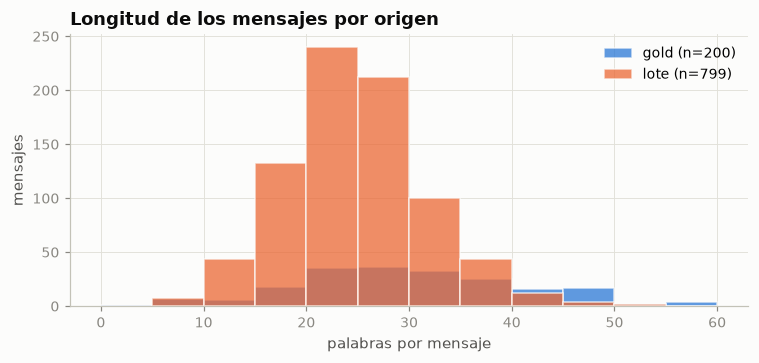

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.arange(0, df["palabras"].max() + 5, 5)
for i, (origen, g) in enumerate(df.groupby("origen")):
    ax.hist(g["palabras"], bins=bins, alpha=0.75, color=graficos.SERIES[i], label=f"{origen} (n={len(g)})", edgecolor=graficos.SUPERFICIE, linewidth=1)
ax.set_xlabel("palabras por mensaje")
ax.set_ylabel("mensajes")
ax.set_title("Longitud de los mensajes por origen", loc="left")
ax.legend()
fig.tight_layout()

## Acuerdo entre etiquetadores

El acuerdo se mide sobre las etiquetas finales del JSON, derivadas con las mismas reglas a partir de las anotaciones de cada etiquetador. Se reporta el porcentaje de coincidencia y el kappa de Cohen, que corrige el acuerdo esperado por azar.

In [7]:
ref = {f["id"]: f for s in splits.values() for f in s}
otro = leer_jsonl("../data/reetiquetado/reetiquetado_150.jsonl")
a = [ref[o["id"]]["salida"] for o in otro]
b = [esquema.construir_salida(o["intencion"], o["atributos"], o["slots"]) for o in otro]
filas_k = []
for c in campos:
    x, y = [str(r[c]) for r in a], [str(r[c]) for r in b]
    filas_k.append({"campo": c, "acuerdo": np.mean([i == j for i, j in zip(x, y)]), "kappa": cohen_kappa_score(x, y)})
for k in esquema.SLOTS:
    norm = lambda v: esquema.normalizar_texto(v) if isinstance(v, str) else v
    filas_k.append({"campo": f"slot {k}", "acuerdo": np.mean([norm(r["slots"][k]) == norm(s["slots"][k]) for r, s in zip(a, b)]), "kappa": np.nan})
pd.DataFrame(filas_k).round(3)

,campo,acuerdo,kappa
0,intencion,0.980,0.977
1,agente,0.993,0.990
2,prioridad,0.993,0.990
3,requiere_aprobacion_humana,1.000,1.000
4,slot destino,0.993,NaN
5,slot fecha,0.987,NaN
6,slot n_personas,0.993,NaN
7,slot monto,1.000,NaN


El acuerdo es casi perfecto en todos los campos, con kappa entre 0.98 y 1.00. Este resultado refleja sobre todo que las reglas de la guía son precisas y reproducibles. Las discrepancias observadas se concentran en fronteras previstas por la guía, como una queja con un cobro objetado sin pedido explícito de devolución o la elección entre dos destinos mencionados en el mismo mensaje.